# EEE3032 – Stage 9: Query-Adaptive and Rank-Based Fusion

This notebook extends Stage 8 by investigating whether BoVW can complement MobileNetV3-Small on individual queries, even though MobileNet is stronger overall.

**Research question:** can rank-based fusion, query-wise score normalisation, or a confidence-guided query-adaptive fusion improve development-set retrieval compared with the fixed-weight score fusion tested in Stage 8?

The notebook evaluates only the **100 development queries**. The final test queries are loaded only as part of the supplied split interface and are not inspected, scored, or used to select parameters.

Experiments:

1. **Oracle diagnostic:** estimate the maximum potential of query-specific weighting by selecting the best Stage 8 alpha separately for each query. This is an analysis-only upper bound because it uses relevance labels.
2. **Weighted Reciprocal Rank Fusion (RRF):** combine the two rankings rather than their raw cosine scores.
3. **Query-wise score normalisation:** compare min-max and z-score normalisation before score-level fusion.
4. **Confidence-guided adaptive RRF:** estimate each model's ranking confidence from its score separation and assign a different BoVW contribution to each query, without using the query's true category.

Group labels are used only for evaluation and analysis. They are never used to decide a query's fusion weight.

## 1. Connect to the project and load the fixed split

Use the same project paths as Stages 6–8. Run Stage 8 first because Stage 9 reads the saved development similarity matrices from that notebook.

In [1]:
from pathlib import Path
import sys
import csv
import json
import re
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3"
)
DATASET_SOURCE = Path(
    "/content/drive/MyDrive/cvpr_coursework/MSRC_ObjCategImageDatabase_v2"
)

if not (PROJECT_ROOT / "cvpr" / "dataset.py").is_file():
    raise FileNotFoundError("Set PROJECT_ROOT to the folder containing cvpr/dataset.py.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from cvpr.dataset import load_split_records, read_rgb
from cvpr.evaluation import average_precision, precision_at_k, per_category_summary

MANIFEST = PROJECT_ROOT / "split_manifest.csv"
gallery, dev, _test_records = load_split_records(
    DATASET_SOURCE,
    manifest_path=MANIFEST,
    extract_dir=PROJECT_ROOT / "data",
)

gallery_names = np.asarray([record.filename for record in gallery])
dev_names = np.asarray([record.filename for record in dev])

assert len(gallery) == 391
assert len(dev) == 100

print(f"Gallery={len(gallery)}, development={len(dev)}")
print("Final test queries are not evaluated in this notebook.")

Mounted at /content/drive
Gallery=391, development=100
Final test queries are not evaluated in this notebook.


## 2. Set the experiment and load Stage 8 similarity matrices

Stage 8 stores one BoVW and one MobileNet similarity score for every development-query/gallery-image pair. Loading these matrices keeps the Stage 9 experiments directly comparable with Stage 8 and avoids repeating descriptor extraction.

In [2]:
P_AT_K = 10
STAGE8_ALPHAS = [0.0, 0.25, 0.50, 0.75, 1.0]

RESULTS_DIR = PROJECT_ROOT / "results"
VISUAL_DIR = RESULTS_DIR / "stage9_fusion_visual_examples"
VISUAL_DIR.mkdir(parents=True, exist_ok=True)

STAGE8_SIMILARITY_FILE = RESULTS_DIR / "stage8_dev_similarity_matrices.npz"
STAGE8_SELECTION_FILE = RESULTS_DIR / "stage8_selected_fusion.json"
if not STAGE8_SIMILARITY_FILE.exists():
    raise FileNotFoundError(
        f"Cannot find {STAGE8_SIMILARITY_FILE}. Run Stage 8 first."
    )
if not STAGE8_SELECTION_FILE.exists():
    raise FileNotFoundError(
        f"Cannot find {STAGE8_SELECTION_FILE}. Run Stage 8 first."
    )

with np.load(STAGE8_SIMILARITY_FILE, allow_pickle=False) as saved:
    saved_gallery_names = saved["gallery_filenames"].astype(str)
    saved_dev_names = saved["dev_filenames"].astype(str)
    S_BOVW = np.asarray(saved["bovw_similarity"], dtype=np.float32)
    S_DEEP = np.asarray(saved["deep_similarity"], dtype=np.float32)
    STAGE8_BEST_ALPHA = float(saved["best_alpha"])

with STAGE8_SELECTION_FILE.open("r", encoding="utf-8") as handle:
    stage8_selection = json.load(handle)
CORE_CONFIG = stage8_selection["core_configuration"]
K = int(stage8_selection["core_vocabulary_size"])

if not np.array_equal(saved_gallery_names, gallery_names):
    raise ValueError("Stage 8 gallery filename order does not match the official split.")
if not np.array_equal(saved_dev_names, dev_names):
    raise ValueError("Stage 8 development filename order does not match the official split.")
if S_BOVW.shape != (len(dev), len(gallery)):
    raise ValueError(f"Unexpected BoVW similarity shape: {S_BOVW.shape}")
if S_DEEP.shape != (len(dev), len(gallery)):
    raise ValueError(f"Unexpected deep similarity shape: {S_DEEP.shape}")
if not np.isfinite(S_BOVW).all() or not np.isfinite(S_DEEP).all():
    raise ValueError("A Stage 8 similarity matrix contains non-finite values.")

print("Loaded BoVW similarity matrix:", S_BOVW.shape)
print("Loaded MobileNet similarity matrix:", S_DEEP.shape)
print("Stage 8 selected alpha:", STAGE8_BEST_ALPHA)
print("BoVW score range:", (float(S_BOVW.min()), float(S_BOVW.max())))
print("Deep score range:", (float(S_DEEP.min()), float(S_DEEP.max())))

Loaded BoVW similarity matrix: (100, 391)
Loaded MobileNet similarity matrix: (100, 391)
Stage 8 selected alpha: 0.0
BoVW score range: (0.0, 0.9943150877952576)
Deep score range: (-0.3608335256576538, 0.9718774557113647)


## 3. Define the coursework evaluation helper

This uses the same AP and P@10 functions as Stage 8. Each query is ranked by descending similarity, and relevance is determined by the supplied retrieval-group category.

In [3]:
def evaluate_similarity_matrix(query_records, gallery_records, similarity_matrix, k=10):
    """Evaluate descending query-to-gallery similarities using coursework metrics."""
    scores = np.asarray(similarity_matrix, dtype=np.float64)
    if scores.shape != (len(query_records), len(gallery_records)):
        raise ValueError(
            f"Similarity shape {scores.shape} does not match "
            f"({len(query_records)}, {len(gallery_records)})."
        )
    if not np.isfinite(scores).all():
        raise ValueError("Similarity matrix contains non-finite values.")

    gallery_categories = np.asarray(
        [record.category for record in gallery_records], dtype=int
    )
    rows = []
    for query_index, query_record in enumerate(query_records):
        ranked_indices = np.argsort(-scores[query_index], kind="stable")
        relevance = gallery_categories[ranked_indices] == int(query_record.category)
        total_relevant = int(
            np.sum(gallery_categories == int(query_record.category))
        )

        rows.append({
            "filename": query_record.filename,
            "category": int(query_record.category),
            "AP": average_precision(relevance, total_relevant=total_relevant),
            f"P@{k}": precision_at_k(relevance, k=k),
        })

    ap_values = np.asarray([row["AP"] for row in rows], dtype=float)
    p_values = np.asarray([row[f"P@{k}"] for row in rows], dtype=float)
    summary = {
        "n_queries": len(rows),
        "mAP": float(ap_values.mean()),
        f"mean_P@{k}": float(p_values.mean()),
    }
    return summary, rows


def save_rows_to_csv(rows, output_file):
    """Save a list of dictionaries to CSV."""
    if not rows:
        raise ValueError(f"No rows to save to {output_file}")
    output_file.parent.mkdir(parents=True, exist_ok=True)
    with output_file.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0].keys()))
        writer.writeheader()
        writer.writerows(rows)


# Recalculate the two pure controls from the saved matrices.
bovw_summary, bovw_query_rows = evaluate_similarity_matrix(
    dev, gallery, S_BOVW, k=P_AT_K
)
deep_summary, deep_query_rows = evaluate_similarity_matrix(
    dev, gallery, S_DEEP, k=P_AT_K
)

print(
    f"BoVW mAP: {bovw_summary['mAP']:.4f} | "
    f"mean P@10: {bovw_summary['mean_P@10']:.4f}"
)
print(
    f"MobileNet mAP: {deep_summary['mAP']:.4f} | "
    f"mean P@10: {deep_summary['mean_P@10']:.4f}"
)

BoVW mAP: 0.2511 | mean P@10: 0.2910
MobileNet mAP: 0.6726 | mean P@10: 0.7350


## 4. Oracle diagnostic: is query-specific fusion worth investigating?

For each development query, this diagnostic finds which of the five Stage 8 alpha values gives the highest AP. The average of those per-query maxima is an optimistic **oracle upper bound** for this alpha grid.



In [4]:
STAGE8_QUERY_ROWS = {}
STAGE8_AP_MATRIX = []
STAGE8_P10_MATRIX = []

for alpha in STAGE8_ALPHAS:
    fused_similarity = alpha * S_BOVW + (1.0 - alpha) * S_DEEP
    _, query_rows = evaluate_similarity_matrix(
        dev, gallery, fused_similarity, k=P_AT_K
    )
    STAGE8_QUERY_ROWS[alpha] = query_rows
    STAGE8_AP_MATRIX.append([row["AP"] for row in query_rows])
    STAGE8_P10_MATRIX.append([row["P@10"] for row in query_rows])

STAGE8_AP_MATRIX = np.asarray(STAGE8_AP_MATRIX, dtype=float)
STAGE8_P10_MATRIX = np.asarray(STAGE8_P10_MATRIX, dtype=float)

oracle_best_indices = np.argmax(STAGE8_AP_MATRIX, axis=0)
oracle_best_alphas = np.asarray(STAGE8_ALPHAS)[oracle_best_indices]
oracle_best_ap = STAGE8_AP_MATRIX[oracle_best_indices, np.arange(len(dev))]
oracle_best_p10 = STAGE8_P10_MATRIX[oracle_best_indices, np.arange(len(dev))]

fixed_alpha_maps = STAGE8_AP_MATRIX.mean(axis=1)
best_fixed_grid_map = float(fixed_alpha_maps.max())
oracle_map = float(oracle_best_ap.mean())

oracle_rows = []
for index, record in enumerate(dev):
    oracle_rows.append({
        "filename": record.filename,
        "category": int(record.category),
        "oracle_alpha_by_AP": float(oracle_best_alphas[index]),
        "oracle_AP": float(oracle_best_ap[index]),
        "P@10_at_oracle_AP_alpha": float(oracle_best_p10[index]),
        "MobileNet_AP": float(STAGE8_AP_MATRIX[0, index]),
        "BoVW_AP": float(STAGE8_AP_MATRIX[-1, index]),
    })

print(f"Best fixed Stage 8 alpha-grid mAP: {best_fixed_grid_map:.4f}")
print(f"Per-query oracle mAP (upper bound): {oracle_map:.4f}")
print(f"Oracle headroom over best fixed alpha: {oracle_map - best_fixed_grid_map:+.4f}")
print("\nNumber of queries selecting each oracle alpha:")
for alpha in STAGE8_ALPHAS:
    print(f"  alpha={alpha:.2f}: {int(np.sum(oracle_best_alphas == alpha))}")

save_rows_to_csv(oracle_rows, RESULTS_DIR / "stage9_dev_oracle_diagnostic.csv")

Best fixed Stage 8 alpha-grid mAP: 0.6726
Per-query oracle mAP (upper bound): 0.6839
Oracle headroom over best fixed alpha: +0.0113

Number of queries selecting each oracle alpha:
  alpha=0.00: 74
  alpha=0.25: 22
  alpha=0.50: 3
  alpha=0.75: 1
  alpha=1.00: 0


## 5. Weighted Reciprocal Rank Fusion (RRF)

Raw cosine scores from BoVW and MobileNet have different distributions. RRF avoids directly adding these values. It converts each model's ranking into reciprocal-rank scores and then combines them:

\[
S_{RRF}(q,g)=\frac{\alpha}{c+r_B(q,g)}+
\frac{1-\alpha}{c+r_D(q,g)}
\]

Here, rank 1 is the best result, \(c\) is a smoothing constant, and \(\alpha\) is the BoVW contribution. We include both pure-model controls.

In [5]:
def similarity_to_ranks(similarity_matrix):
    """Convert each row of descending similarity scores into ranks (1 = best)."""
    scores = np.asarray(similarity_matrix, dtype=np.float64)
    order = np.argsort(-scores, axis=1, kind="stable")
    ranks = np.empty_like(order)
    row_indices = np.arange(scores.shape[0])[:, None]
    ranks[row_indices, order] = np.arange(1, scores.shape[1] + 1)
    return ranks


RRF_CONSTANT = 60
RRF_ALPHAS = [0.0, 0.05, 0.10, 0.15, 0.25, 0.40, 0.50, 0.75, 1.0]

bovw_ranks = similarity_to_ranks(S_BOVW)
deep_ranks = similarity_to_ranks(S_DEEP)

bovw_rrf_scores = 1.0 / (RRF_CONSTANT + bovw_ranks)
deep_rrf_scores = 1.0 / (RRF_CONSTANT + deep_ranks)

rrf_rows = []
rrf_query_rows = {}
rrf_group_rows = {}
rrf_similarity_matrices = {}

for alpha in RRF_ALPHAS:
    fused_similarity = (
        alpha * bovw_rrf_scores
        + (1.0 - alpha) * deep_rrf_scores
    )
    summary, query_rows = evaluate_similarity_matrix(
        dev, gallery, fused_similarity, k=P_AT_K
    )
    group_rows = per_category_summary(query_rows, k=P_AT_K)

    if alpha == 0.0:
        label = "MobileNet rank only"
    elif alpha == 1.0:
        label = "BoVW rank only"
    else:
        label = f"Weighted RRF alpha={alpha:.2f}"

    rrf_rows.append({
        "method": label,
        "alpha_bovw": float(alpha),
        "rrf_constant": int(RRF_CONSTANT),
        "mAP": float(summary["mAP"]),
        "mean_P@10": float(summary["mean_P@10"]),
        "n_queries": int(summary["n_queries"]),
    })
    rrf_query_rows[alpha] = query_rows
    rrf_group_rows[alpha] = group_rows
    rrf_similarity_matrices[alpha] = fused_similarity

best_rrf_row = max(
    rrf_rows,
    key=lambda row: (
        row["mAP"], row["mean_P@10"], -abs(row["alpha_bovw"] - 0.5)
    ),
)
BEST_RRF_ALPHA = float(best_rrf_row["alpha_bovw"])
BEST_RRF_SIMILARITY = rrf_similarity_matrices[BEST_RRF_ALPHA]
BEST_RRF_QUERY_ROWS = rrf_query_rows[BEST_RRF_ALPHA]
BEST_RRF_GROUP_ROWS = rrf_group_rows[BEST_RRF_ALPHA]

print(f"{'Method':34s} {'alpha':>7s} {'mAP':>10s} {'Mean P@10':>12s}")
print("-" * 68)
for row in rrf_rows:
    print(
        f"{row['method']:34s} {row['alpha_bovw']:7.2f} "
        f"{row['mAP']:10.4f} {row['mean_P@10']:12.4f}"
    )
print("\nSelected RRF alpha:", BEST_RRF_ALPHA)

Method                               alpha        mAP    Mean P@10
--------------------------------------------------------------------
MobileNet rank only                   0.00     0.6726       0.7350
Weighted RRF alpha=0.05               0.05     0.6715       0.7350
Weighted RRF alpha=0.10               0.10     0.6680       0.7310
Weighted RRF alpha=0.15               0.15     0.6632       0.7150
Weighted RRF alpha=0.25               0.25     0.6411       0.6990
Weighted RRF alpha=0.40               0.40     0.5756       0.6250
Weighted RRF alpha=0.50               0.50     0.5146       0.5640
Weighted RRF alpha=0.75               0.75     0.3624       0.4060
BoVW rank only                        1.00     0.2511       0.2910

Selected RRF alpha: 0.0


## 6. Query-wise score normalisation before fusion

This experiment keeps score-level fusion but changes the scale of each model's scores **separately for every query**:

- **Min-max:** rescales each query's gallery scores to [0, 1].
- **Z-score:** subtracts the query's mean score and divides by its standard deviation.

The same alpha grid is evaluated for both normalisation methods. The pure-model endpoints are included as controls. Normalisation changes relative score contributions; it does not use category labels.

In [6]:
def normalise_similarity_rows(similarity_matrix, method):
    """Normalise each query's gallery scores independently."""
    scores = np.asarray(similarity_matrix, dtype=np.float64)

    if method == "minmax":
        row_min = scores.min(axis=1, keepdims=True)
        row_max = scores.max(axis=1, keepdims=True)
        return (scores - row_min) / np.maximum(row_max - row_min, 1e-12)

    if method == "zscore":
        row_mean = scores.mean(axis=1, keepdims=True)
        row_std = scores.std(axis=1, keepdims=True)
        return (scores - row_mean) / np.maximum(row_std, 1e-12)

    raise ValueError("method must be 'minmax' or 'zscore'.")


NORMALISED_ALPHAS = [0.0, 0.05, 0.10, 0.15, 0.25, 0.40, 0.50, 0.75, 1.0]
normalised_rows = []
normalised_query_rows = {}
normalised_group_rows = {}
normalised_similarity_matrices = {}

for normalisation in ["minmax", "zscore"]:
    bovw_normalised = normalise_similarity_rows(S_BOVW, normalisation)
    deep_normalised = normalise_similarity_rows(S_DEEP, normalisation)

    for alpha in NORMALISED_ALPHAS:
        fused_similarity = (
            alpha * bovw_normalised
            + (1.0 - alpha) * deep_normalised
        )
        summary, query_rows = evaluate_similarity_matrix(
            dev, gallery, fused_similarity, k=P_AT_K
        )
        group_rows = per_category_summary(query_rows, k=P_AT_K)
        key = (normalisation, float(alpha))

        normalised_rows.append({
            "normalisation": normalisation,
            "alpha_bovw": float(alpha),
            "mAP": float(summary["mAP"]),
            "mean_P@10": float(summary["mean_P@10"]),
            "n_queries": int(summary["n_queries"]),
        })
        normalised_query_rows[key] = query_rows
        normalised_group_rows[key] = group_rows
        normalised_similarity_matrices[key] = fused_similarity

best_normalised_rows = {}
for normalisation in ["minmax", "zscore"]:
    candidates = [row for row in normalised_rows if row["normalisation"] == normalisation]
    best_row = max(
        candidates,
        key=lambda row: (
            row["mAP"], row["mean_P@10"], -abs(row["alpha_bovw"] - 0.5)
        ),
    )
    best_normalised_rows[normalisation] = best_row

    print(
        f"{normalisation:8s} | best alpha={best_row['alpha_bovw']:.2f} | "
        f"mAP={best_row['mAP']:.4f} | "
        f"mean P@10={best_row['mean_P@10']:.4f}"
    )

minmax   | best alpha=0.00 | mAP=0.6726 | mean P@10=0.7350
zscore   | best alpha=0.00 | mAP=0.6726 | mean P@10=0.7350


## 7. Confidence-guided adaptive RRF

A single alpha treats every query in the same way. This experiment estimates a simple ranking-confidence measure separately for each model and each query.

For each query, scores are sorted from highest to lowest. Confidence is estimated as:

\[
C(q)=\frac{\operatorname{mean}(s_{1:5})-
\operatorname{mean}(s_{6:20})}{\operatorname{std}(s_{1:391})+\epsilon}
\]

A larger gap means the model's top five results are more separated from the next fifteen, relative to the spread of its scores. This is a **heuristic ranking-confidence indicator**, not a calibrated probability of correctness.

The confidence difference is \(\Delta C=C_{BoVW}-C_{Deep}\). We convert it into a query-specific BoVW weight:

\[
\alpha(q)=\alpha_{max}\,\sigma(\beta\Delta C(q))
\]

The gate uses only the two query-to-gallery score rows. It does not use the query's category or AP. A small pre-declared grid of \(\alpha_{max}\) and \(\beta\) values is selected using development mAP.

In [7]:
def ranking_gap_confidence(similarity_matrix, top_k=5, next_k=15):
    """Estimate per-query confidence from the gap between top and following scores."""
    scores = np.asarray(similarity_matrix, dtype=np.float64)
    if scores.shape[1] < top_k + next_k:
        raise ValueError("Not enough gallery images for the selected confidence windows.")

    sorted_scores = np.sort(scores, axis=1)[:, ::-1]
    top_mean = sorted_scores[:, :top_k].mean(axis=1)
    next_mean = sorted_scores[:, top_k:top_k + next_k].mean(axis=1)
    row_std = scores.std(axis=1)
    confidence = (top_mean - next_mean) / np.maximum(row_std, 1e-12)
    return confidence


def sigmoid(values):
    """Numerically stable sigmoid for a NumPy array."""
    values = np.asarray(values, dtype=np.float64)
    values = np.clip(values, -30.0, 30.0)
    return 1.0 / (1.0 + np.exp(-values))


confidence_bovw = ranking_gap_confidence(S_BOVW)
confidence_deep = ranking_gap_confidence(S_DEEP)
confidence_difference = confidence_bovw - confidence_deep

print("BoVW confidence range:", (float(confidence_bovw.min()), float(confidence_bovw.max())))
print("Deep confidence range:", (float(confidence_deep.min()), float(confidence_deep.max())))
print("Confidence difference range:", (
    float(confidence_difference.min()), float(confidence_difference.max())
))

ADAPTIVE_ALPHA_MAX_VALUES = [0.10, 0.20, 0.30, 0.40]
ADAPTIVE_BETA_VALUES = [0.25, 0.50, 1.00]

adaptive_rows = []
adaptive_query_rows = {}
adaptive_group_rows = {}
adaptive_similarity_matrices = {}
adaptive_alpha_vectors = {}

for alpha_max in ADAPTIVE_ALPHA_MAX_VALUES:
    for beta in ADAPTIVE_BETA_VALUES:
        query_alphas = alpha_max * sigmoid(beta * confidence_difference)
        fused_similarity = (
            query_alphas[:, None] * bovw_rrf_scores
            + (1.0 - query_alphas[:, None]) * deep_rrf_scores
        )

        summary, query_rows = evaluate_similarity_matrix(
            dev, gallery, fused_similarity, k=P_AT_K
        )
        group_rows = per_category_summary(query_rows, k=P_AT_K)
        key = (float(alpha_max), float(beta))

        adaptive_rows.append({
            "alpha_max": float(alpha_max),
            "beta": float(beta),
            "mAP": float(summary["mAP"]),
            "mean_P@10": float(summary["mean_P@10"]),
            "mean_query_alpha": float(query_alphas.mean()),
            "minimum_query_alpha": float(query_alphas.min()),
            "maximum_query_alpha": float(query_alphas.max()),
            "n_queries": int(summary["n_queries"]),
        })
        adaptive_query_rows[key] = query_rows
        adaptive_group_rows[key] = group_rows
        adaptive_similarity_matrices[key] = fused_similarity
        adaptive_alpha_vectors[key] = query_alphas

best_adaptive_row = max(
    adaptive_rows,
    key=lambda row: (
        row["mAP"], row["mean_P@10"], -row["alpha_max"], -row["beta"]
    ),
)
BEST_ADAPTIVE_KEY = (
    float(best_adaptive_row["alpha_max"]),
    float(best_adaptive_row["beta"]),
)
BEST_ADAPTIVE_SIMILARITY = adaptive_similarity_matrices[BEST_ADAPTIVE_KEY]
BEST_ADAPTIVE_QUERY_ROWS = adaptive_query_rows[BEST_ADAPTIVE_KEY]
BEST_ADAPTIVE_GROUP_ROWS = adaptive_group_rows[BEST_ADAPTIVE_KEY]
BEST_ADAPTIVE_ALPHAS = adaptive_alpha_vectors[BEST_ADAPTIVE_KEY]

print(f"{'alpha_max':>10s} {'beta':>8s} {'mAP':>10s} {'Mean P@10':>12s} {'mean alpha(q)':>15s}")
print("-" * 62)
for row in adaptive_rows:
    print(
        f"{row['alpha_max']:10.2f} {row['beta']:8.2f} "
        f"{row['mAP']:10.4f} {row['mean_P@10']:12.4f} "
        f"{row['mean_query_alpha']:15.4f}"
    )

print("\nSelected adaptive setting:", BEST_ADAPTIVE_KEY)

BoVW confidence range: (0.18518270928925526, 2.3688537343893787)
Deep confidence range: (0.1464420439799522, 1.9265915338569395)
Confidence difference range: (-1.6476722822888765, 1.9499737623926936)
 alpha_max     beta        mAP    Mean P@10   mean alpha(q)
--------------------------------------------------------------
      0.10     0.25     0.6716       0.7360          0.0502
      0.10     0.50     0.6718       0.7360          0.0504
      0.10     1.00     0.6725       0.7350          0.0509
      0.20     0.25     0.6686       0.7310          0.1004
      0.20     0.50     0.6690       0.7320          0.1009
      0.20     1.00     0.6711       0.7340          0.1017
      0.30     0.25     0.6643       0.7170          0.1507
      0.30     0.50     0.6649       0.7200          0.1513
      0.30     1.00     0.6666       0.7220          0.1526
      0.40     0.25     0.6566       0.7140          0.2009
      0.40     0.50     0.6568       0.7160          0.2017
      0.40     1.

## 8. Compare all methods on development queries

The comparison includes the pure BoVW and MobileNet controls, the Stage 8 fixed score fusion, the best min-max and z-score variants, the best fixed RRF setting, and the best confidence-guided adaptive RRF setting.

The highest development mAP is the selection criterion; mean P@10 is used as a tie-breaker. This is still development-set selection, not an estimate of final test performance.

In [8]:
# Recover the selected normalised score matrices and their query-level results.
best_minmax_row = best_normalised_rows["minmax"]
best_zscore_row = best_normalised_rows["zscore"]

BEST_MINMAX_KEY = ("minmax", float(best_minmax_row["alpha_bovw"]))
BEST_ZSCORE_KEY = ("zscore", float(best_zscore_row["alpha_bovw"]))
BEST_MINMAX_SIMILARITY = normalised_similarity_matrices[BEST_MINMAX_KEY]
BEST_ZSCORE_SIMILARITY = normalised_similarity_matrices[BEST_ZSCORE_KEY]
BEST_MINMAX_QUERY_ROWS = normalised_query_rows[BEST_MINMAX_KEY]
BEST_ZSCORE_QUERY_ROWS = normalised_query_rows[BEST_ZSCORE_KEY]

stage8_fixed_similarity = (
    STAGE8_BEST_ALPHA * S_BOVW
    + (1.0 - STAGE8_BEST_ALPHA) * S_DEEP
)
stage8_fixed_summary, stage8_fixed_query_rows = evaluate_similarity_matrix(
    dev, gallery, stage8_fixed_similarity, k=P_AT_K
)

method_entries = [
    ("MobileNetV3-Small", S_DEEP, deep_query_rows),
    (f"BoVW ({CORE_CONFIG})", S_BOVW, bovw_query_rows),
    (f"Stage 8 fixed score fusion (alpha={STAGE8_BEST_ALPHA:.2f})",
     stage8_fixed_similarity, stage8_fixed_query_rows),
    (f"Min-max fusion (alpha={best_minmax_row['alpha_bovw']:.2f})",
     BEST_MINMAX_SIMILARITY, BEST_MINMAX_QUERY_ROWS),
    (f"Z-score fusion (alpha={best_zscore_row['alpha_bovw']:.2f})",
     BEST_ZSCORE_SIMILARITY, BEST_ZSCORE_QUERY_ROWS),
    (f"Weighted RRF (alpha={BEST_RRF_ALPHA:.2f})",
     BEST_RRF_SIMILARITY, BEST_RRF_QUERY_ROWS),
    (f"Adaptive RRF (max={BEST_ADAPTIVE_KEY[0]:.2f}, beta={BEST_ADAPTIVE_KEY[1]:.2f})",
     BEST_ADAPTIVE_SIMILARITY, BEST_ADAPTIVE_QUERY_ROWS),
]

method_comparison_rows = []
all_method_query_rows = []
all_method_group_rows = []

for method_name, similarity_matrix, query_rows in method_entries:
    summary, _ = evaluate_similarity_matrix(
        dev, gallery, similarity_matrix, k=P_AT_K
    )
    method_comparison_rows.append({
        "method": method_name,
        "mAP": float(summary["mAP"]),
        "mean_P@10": float(summary["mean_P@10"]),
        "n_queries": int(summary["n_queries"]),
    })
    all_method_query_rows.extend([
        {"method": method_name, **row} for row in query_rows
    ])
    all_method_group_rows.extend([
        {"method": method_name, **row}
        for row in per_category_summary(query_rows, k=P_AT_K)
    ])

method_comparison_rows = sorted(
    method_comparison_rows,
    key=lambda row: (row["mAP"], row["mean_P@10"]),
    reverse=True,
)

print(f"{'Method':58s} {'mAP':>9s} {'Mean P@10':>12s}")
print("-" * 82)
for row in method_comparison_rows:
    print(
        f"{row['method']:58s} {row['mAP']:9.4f} "
        f"{row['mean_P@10']:12.4f}"
    )

BEST_STAGE9_METHOD = method_comparison_rows[0]["method"]
print("\nBest development method among tested candidates:", BEST_STAGE9_METHOD)

Method                                                           mAP    Mean P@10
----------------------------------------------------------------------------------
MobileNetV3-Small                                             0.6726       0.7350
Stage 8 fixed score fusion (alpha=0.00)                       0.6726       0.7350
Min-max fusion (alpha=0.00)                                   0.6726       0.7350
Z-score fusion (alpha=0.00)                                   0.6726       0.7350
Weighted RRF (alpha=0.00)                                     0.6726       0.7350
Adaptive RRF (max=0.10, beta=1.00)                            0.6725       0.7350
BoVW (dense_root_opponentsift)                                0.2511       0.2910

Best development method among tested candidates: MobileNetV3-Small


## 9. Plot the fusion experiments

These plots help show whether rank fusion or score normalisation offers a consistent gain, and whether the adaptive gate improves on the MobileNet-only control.

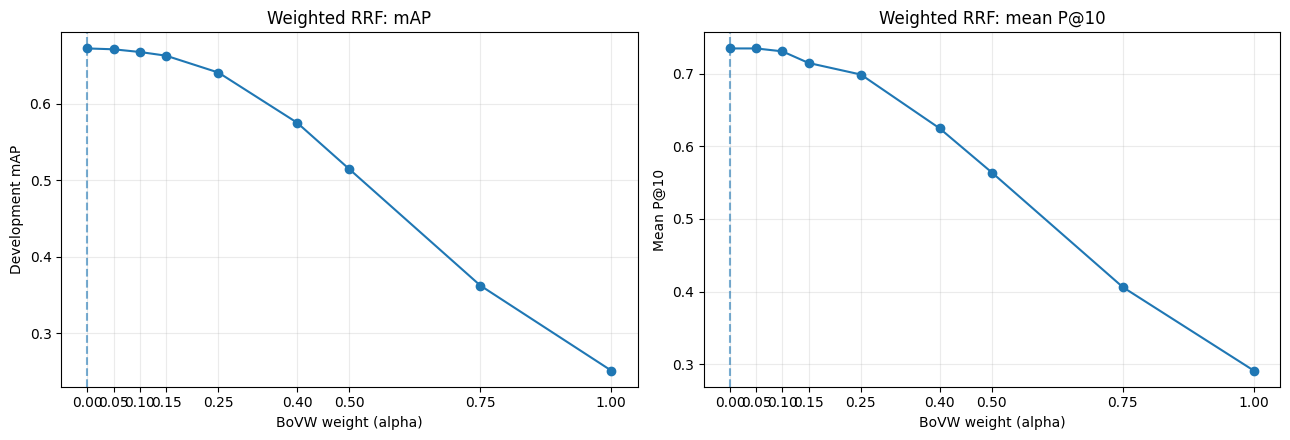

Saved: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage9_dev_rrf_sweep.png


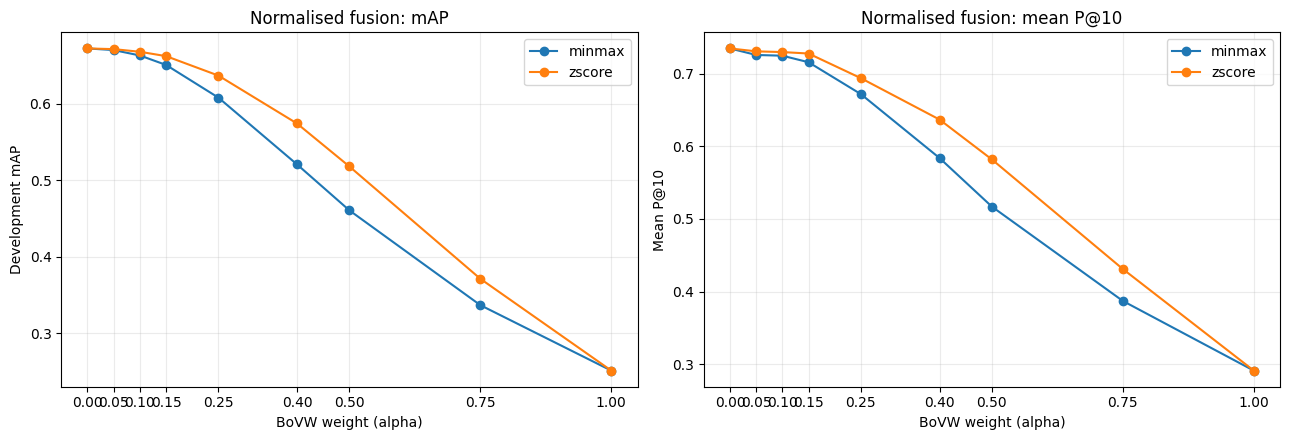

Saved: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage9_dev_normalised_fusion_sweep.png


In [9]:
# Weighted RRF sweep.
rrf_alpha_values = [row["alpha_bovw"] for row in rrf_rows]
rrf_map_values = [row["mAP"] for row in rrf_rows]
rrf_p10_values = [row["mean_P@10"] for row in rrf_rows]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(rrf_alpha_values, rrf_map_values, marker="o")
axes[0].axvline(BEST_RRF_ALPHA, linestyle="--", alpha=0.6)
axes[0].set_xlabel("BoVW weight (alpha)")
axes[0].set_ylabel("Development mAP")
axes[0].set_title("Weighted RRF: mAP")
axes[0].set_xticks(RRF_ALPHAS)
axes[0].grid(alpha=0.25)

axes[1].plot(rrf_alpha_values, rrf_p10_values, marker="o")
axes[1].axvline(BEST_RRF_ALPHA, linestyle="--", alpha=0.6)
axes[1].set_xlabel("BoVW weight (alpha)")
axes[1].set_ylabel("Mean P@10")
axes[1].set_title("Weighted RRF: mean P@10")
axes[1].set_xticks(RRF_ALPHAS)
axes[1].grid(alpha=0.25)

fig.tight_layout()
rrf_plot_file = RESULTS_DIR / "stage9_dev_rrf_sweep.png"
fig.savefig(rrf_plot_file, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", rrf_plot_file)


# Min-max and z-score normalised score-fusion sweeps.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for normalisation in ["minmax", "zscore"]:
    rows = [row for row in normalised_rows if row["normalisation"] == normalisation]
    axes[0].plot(
        [row["alpha_bovw"] for row in rows],
        [row["mAP"] for row in rows],
        marker="o", label=normalisation,
    )
    axes[1].plot(
        [row["alpha_bovw"] for row in rows],
        [row["mean_P@10"] for row in rows],
        marker="o", label=normalisation,
    )

axes[0].set_xlabel("BoVW weight (alpha)")
axes[0].set_ylabel("Development mAP")
axes[0].set_title("Normalised fusion: mAP")
axes[0].set_xticks(NORMALISED_ALPHAS)
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].set_xlabel("BoVW weight (alpha)")
axes[1].set_ylabel("Mean P@10")
axes[1].set_title("Normalised fusion: mean P@10")
axes[1].set_xticks(NORMALISED_ALPHAS)
axes[1].grid(alpha=0.25)
axes[1].legend()

fig.tight_layout()
normalised_plot_file = RESULTS_DIR / "stage9_dev_normalised_fusion_sweep.png"
fig.savefig(normalised_plot_file, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", normalised_plot_file)

## 10. Inspect the adaptive weights

This section checks whether the confidence gate actually assigns different BoVW weights to different queries. A spread of weights is necessary for query-adaptive fusion, but by itself does not prove that the weights are useful.

Adaptive query alpha statistics:
  Mean: 0.05085518661523762
  Std: 0.012218597913462236
  Min: 0.016142379549481677
  Max: 0.08754437808404453


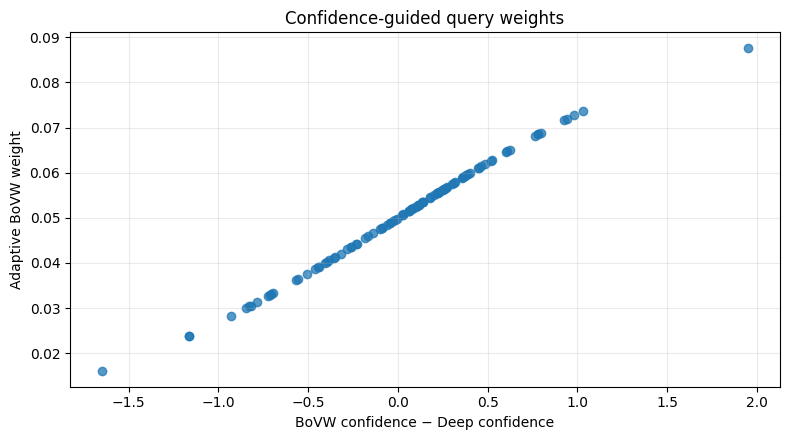

Saved: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage9_dev_adaptive_weights.png


In [10]:
adaptive_alpha_rows = []
for index, record in enumerate(dev):
    adaptive_alpha_rows.append({
        "filename": record.filename,
        "category": int(record.category),
        "BoVW_confidence": float(confidence_bovw[index]),
        "Deep_confidence": float(confidence_deep[index]),
        "confidence_difference": float(confidence_difference[index]),
        "adaptive_alpha_bovw": float(BEST_ADAPTIVE_ALPHAS[index]),
        "AP_adaptive_RRF": float(BEST_ADAPTIVE_QUERY_ROWS[index]["AP"]),
        "P@10_adaptive_RRF": float(BEST_ADAPTIVE_QUERY_ROWS[index]["P@10"]),
    })

print("Adaptive query alpha statistics:")
print("  Mean:", float(BEST_ADAPTIVE_ALPHAS.mean()))
print("  Std:", float(BEST_ADAPTIVE_ALPHAS.std()))
print("  Min:", float(BEST_ADAPTIVE_ALPHAS.min()))
print("  Max:", float(BEST_ADAPTIVE_ALPHAS.max()))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(confidence_difference, BEST_ADAPTIVE_ALPHAS, alpha=0.75)
ax.set_xlabel("BoVW confidence − Deep confidence")
ax.set_ylabel("Adaptive BoVW weight")
ax.set_title("Confidence-guided query weights")
ax.grid(alpha=0.25)
fig.tight_layout()

adaptive_plot_file = RESULTS_DIR / "stage9_dev_adaptive_weights.png"
fig.savefig(adaptive_plot_file, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", adaptive_plot_file)

## 11. Compare group-wise performance

The group-wise results show whether a method helps or harms particular retrieval groups. There are only five development queries per group, so these values should be treated as descriptive evidence rather than precise estimates.

No group-specific alpha is fitted. This avoids using the true group label to choose the fusion strategy for a query and avoids estimating 20 separate weights from only five development queries each.

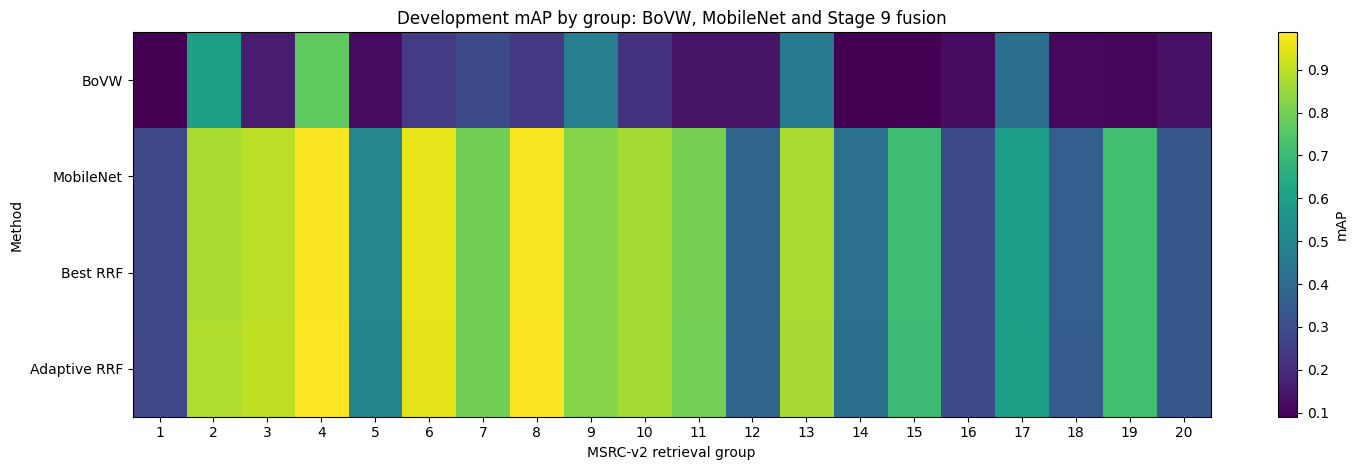

Saved per-group results: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage9_dev_per_group.csv
Saved per-query results: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage9_dev_per_query.csv
Saved method comparison: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage9_dev_method_comparison.csv
Saved group heatmap: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage9_dev_group_comparison.png


In [11]:
# Per-group table for every evaluated method.
group_comparison_file = RESULTS_DIR / "stage9_dev_per_group.csv"
query_comparison_file = RESULTS_DIR / "stage9_dev_per_query.csv"
method_comparison_file = RESULTS_DIR / "stage9_dev_method_comparison.csv"

save_rows_to_csv(all_method_group_rows, group_comparison_file)
save_rows_to_csv(all_method_query_rows, query_comparison_file)
save_rows_to_csv(method_comparison_rows, method_comparison_file)

# Focused heatmap: pure methods, best fixed RRF and adaptive RRF.
heatmap_methods = [
    ("BoVW", bovw_query_rows),
    ("MobileNet", deep_query_rows),
    ("Best RRF", BEST_RRF_QUERY_ROWS),
    ("Adaptive RRF", BEST_ADAPTIVE_QUERY_ROWS),
]

categories = sorted({int(record.category) for record in dev})
heatmap_matrix = []
for method_name, query_rows in heatmap_methods:
    group_rows = per_category_summary(query_rows, k=P_AT_K)
    lookup = {int(row["category"]): float(row["mAP"]) for row in group_rows}
    heatmap_matrix.append([lookup[category] for category in categories])

heatmap_matrix = np.asarray(heatmap_matrix, dtype=float)
fig, ax = plt.subplots(figsize=(15, 4.8))
image = ax.imshow(heatmap_matrix, aspect="auto", interpolation="nearest")
ax.set_title("Development mAP by group: BoVW, MobileNet and Stage 9 fusion")
ax.set_xlabel("MSRC-v2 retrieval group")
ax.set_ylabel("Method")
ax.set_yticks(range(len(heatmap_methods)))
ax.set_yticklabels([item[0] for item in heatmap_methods])
ax.set_xticks(range(len(categories)))
ax.set_xticklabels(categories)
colourbar = fig.colorbar(image, ax=ax)
colourbar.set_label("mAP")
fig.tight_layout()

group_plot_file = RESULTS_DIR / "stage9_dev_group_comparison.png"
fig.savefig(group_plot_file, dpi=180, bbox_inches="tight")
plt.show()

print("Saved per-group results:", group_comparison_file)
print("Saved per-query results:", query_comparison_file)
print("Saved method comparison:", method_comparison_file)
print("Saved group heatmap:", group_plot_file)

## 12. Inspect representative retrieval examples

The examples compare BoVW, MobileNet and the selected adaptive RRF. One query is selected where adaptive RRF improves AP most relative to MobileNet, and one where it changes AP most negatively. These examples help explain the numerical results.

In [12]:
deep_ap = np.asarray([row["AP"] for row in deep_query_rows], dtype=float)
adaptive_ap = np.asarray([row["AP"] for row in BEST_ADAPTIVE_QUERY_ROWS], dtype=float)
adaptive_gain_vs_deep = adaptive_ap - deep_ap

most_helped_index = int(np.argmax(adaptive_gain_vs_deep))
most_harmed_index = int(np.argmin(adaptive_gain_vs_deep))
example_indices = [most_helped_index, most_harmed_index]


def show_stage9_retrieval(query_index, top_k=5):
    """Compare the top results from BoVW, MobileNet and adaptive RRF."""
    query_record = dev[query_index]
    systems = [
        (f"BoVW: {CORE_CONFIG}", S_BOVW[query_index]),
        ("MobileNetV3-Small", S_DEEP[query_index]),
        ("Adaptive RRF", BEST_ADAPTIVE_SIMILARITY[query_index]),
    ]

    fig, axes = plt.subplots(
        len(systems), top_k + 1,
        figsize=(3.0 * (top_k + 1), 3.1 * len(systems)),
    )

    for row_index, (label, scores) in enumerate(systems):
        axes[row_index, 0].imshow(read_rgb(query_record.path))
        axes[row_index, 0].set_title(
            f"QUERY\n{query_record.filename}\nGroup {query_record.category}",
            fontsize=9,
        )
        axes[row_index, 0].axis("off")
        axes[row_index, 0].set_ylabel(label, fontsize=9)

        ranked_indices = np.argsort(-scores, kind="stable")[:top_k]
        for rank, gallery_index in enumerate(ranked_indices, start=1):
            result_record = gallery[int(gallery_index)]
            relevant = int(result_record.category) == int(query_record.category)
            axes[row_index, rank].imshow(read_rgb(result_record.path))
            axes[row_index, rank].set_title(
                f"#{rank} | group {result_record.category}\n"
                f"{'Relevant' if relevant else 'Other group'}",
                fontsize=8,
            )
            axes[row_index, rank].axis("off")

    fig.suptitle(
        f"{query_record.filename} | group {query_record.category} | "
        f"Adaptive RRF AP change vs MobileNet: "
        f"{adaptive_gain_vs_deep[query_index]:+.3f} | "
        f"alpha(q)={BEST_ADAPTIVE_ALPHAS[query_index]:.3f}",
        fontsize=12,
    )
    fig.tight_layout()

    safe_name = re.sub(r"[^A-Za-z0-9_.-]+", "_", query_record.filename)
    output_file = VISUAL_DIR / f"stage9_query_{query_index:03d}_{safe_name}.png"
    fig.savefig(output_file, dpi=160, bbox_inches="tight")
    plt.show()
    print("Saved:", output_file)


for query_index in example_indices:
    print(
        f"\n{dev[query_index].filename} | group {dev[query_index].category} | "
        f"BoVW AP={bovw_query_rows[query_index]['AP']:.3f} | "
        f"Deep AP={deep_query_rows[query_index]['AP']:.3f} | "
        f"Adaptive RRF AP={BEST_ADAPTIVE_QUERY_ROWS[query_index]['AP']:.3f} | "
        f"alpha(q)={BEST_ADAPTIVE_ALPHAS[query_index]:.3f} | "
        f"change vs MobileNet={adaptive_gain_vs_deep[query_index]:+.3f}"
    )
    show_stage9_retrieval(query_index, top_k=5)

Output hidden; open in https://colab.research.google.com to view.

## 13. Save Stage 9 results and record the development selection

The CSV files preserve the oracle diagnostic, RRF sweep, normalised-fusion sweep, adaptive-gate sweep, per-query results, per-group results and overall comparison. The NPZ file preserves the Stage 8 inputs and the selected Stage 9 similarity matrices.

The JSON file records development selection only. It explicitly records that the final test set has not been evaluated.

In [13]:
# Save experiment sweeps.
save_rows_to_csv(rrf_rows, RESULTS_DIR / "stage9_dev_rrf_sweep.csv")
save_rows_to_csv(normalised_rows, RESULTS_DIR / "stage9_dev_normalised_fusion_sweep.csv")
save_rows_to_csv(adaptive_rows, RESULTS_DIR / "stage9_dev_adaptive_gate_sweep.csv")
save_rows_to_csv(adaptive_alpha_rows, RESULTS_DIR / "stage9_dev_adaptive_query_weights.csv")
save_rows_to_csv(oracle_rows, RESULTS_DIR / "stage9_dev_oracle_diagnostic.csv")

similarity_file = RESULTS_DIR / "stage9_dev_similarity_matrices.npz"
np.savez_compressed(
    similarity_file,
    gallery_filenames=gallery_names,
    dev_filenames=dev_names,
    bovw_similarity=S_BOVW.astype(np.float32),
    deep_similarity=S_DEEP.astype(np.float32),
    best_rrf_similarity=BEST_RRF_SIMILARITY.astype(np.float32),
    best_adaptive_rrf_similarity=BEST_ADAPTIVE_SIMILARITY.astype(np.float32),
    best_adaptive_alpha_per_query=BEST_ADAPTIVE_ALPHAS.astype(np.float32),
    best_rrf_alpha=np.asarray(BEST_RRF_ALPHA, dtype=np.float32),
    adaptive_alpha_max=np.asarray(BEST_ADAPTIVE_KEY[0], dtype=np.float32),
    adaptive_beta=np.asarray(BEST_ADAPTIVE_KEY[1], dtype=np.float32),
)

selection = {
    "core_configuration": CORE_CONFIG,
    "vocabulary_size": K,
    "stage8_fixed_alpha_bovw": float(STAGE8_BEST_ALPHA),
    "rrf_constant": int(RRF_CONSTANT),
    "best_rrf_alpha_bovw": float(BEST_RRF_ALPHA),
    "best_rrf_development_mAP": float(best_rrf_row["mAP"]),
    "best_rrf_development_mean_P_at_10": float(best_rrf_row["mean_P@10"]),
    "best_minmax_alpha_bovw": float(best_minmax_row["alpha_bovw"]),
    "best_minmax_development_mAP": float(best_minmax_row["mAP"]),
    "best_zscore_alpha_bovw": float(best_zscore_row["alpha_bovw"]),
    "best_zscore_development_mAP": float(best_zscore_row["mAP"]),
    "adaptive_alpha_max": float(BEST_ADAPTIVE_KEY[0]),
    "adaptive_beta": float(BEST_ADAPTIVE_KEY[1]),
    "adaptive_development_mAP": float(best_adaptive_row["mAP"]),
    "adaptive_development_mean_P_at_10": float(best_adaptive_row["mean_P@10"]),
    "best_development_method": BEST_STAGE9_METHOD,
    "oracle_development_mAP_upper_bound": float(oracle_map),
    "oracle_headroom_over_best_stage8_alpha": float(oracle_map - best_fixed_grid_map),
    "test_evaluated": False,
    "selection_rule": "Development mAP; tie-break by mean P@10. Oracle diagnostic is not a deployable method.",
}

selection_file = RESULTS_DIR / "stage9_selected_fusion.json"
with selection_file.open("w", encoding="utf-8") as handle:
    json.dump(selection, handle, indent=2)

print("Saved RRF sweep:", RESULTS_DIR / "stage9_dev_rrf_sweep.csv")
print("Saved normalised fusion sweep:", RESULTS_DIR / "stage9_dev_normalised_fusion_sweep.csv")
print("Saved adaptive gate sweep:", RESULTS_DIR / "stage9_dev_adaptive_gate_sweep.csv")
print("Saved adaptive query weights:", RESULTS_DIR / "stage9_dev_adaptive_query_weights.csv")
print("Saved similarity matrices:", similarity_file)
print("Saved development selection:", selection_file)

Saved RRF sweep: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage9_dev_rrf_sweep.csv
Saved normalised fusion sweep: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage9_dev_normalised_fusion_sweep.csv
Saved adaptive gate sweep: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage9_dev_adaptive_gate_sweep.csv
Saved adaptive query weights: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage9_dev_adaptive_query_weights.csv
Saved similarity matrices: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage9_dev_similarity_matrices.npz
Saved development selection: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage9_selected_fusion.json
